# Práctica 1

Manuel Suano Gallardo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

___
## Fase de análisis y procesamiento de datos

### Estadística descriptiva

In [ ]:
separador = "######################################"

datos = pd.read_csv('housing.csv', sep=',')

## Información estadística básica sobre los datos
print(">> ", datos.shape)

print(separador)
print(datos.info())

print(separador)
# Variables numéricas
columnas_numericas = datos.select_dtypes(include=[np.number]).columns
datos_descr = datos[columnas_numericas].describe().T

datos_descr['IQR'] = datos_descr['75%'] - datos_descr['25%']
datos_descr['mode'] = datos[columnas_numericas].mode().iloc[0]
datos_descr['asimetria'] = datos[columnas_numericas].skew()
datos_descr['curtosis'] = datos[columnas_numericas].kurtosis()

columnas_visibles = ['mean', 'std', 'mode', '50%', 'max', 'min', 'IQR', 'asimetria', 'curtosis']

print(datos_descr[columnas_visibles].round(3))

print(separador)
print(datos['ocean_proximity'].value_counts())

>>  (20640, 10)
######################################
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
None
######################################
                          mean         std        mode         50%        max  \
longitude             -119.570       2.004    -118.310    -118.490    -114.31   
latit

### Visualización de datos

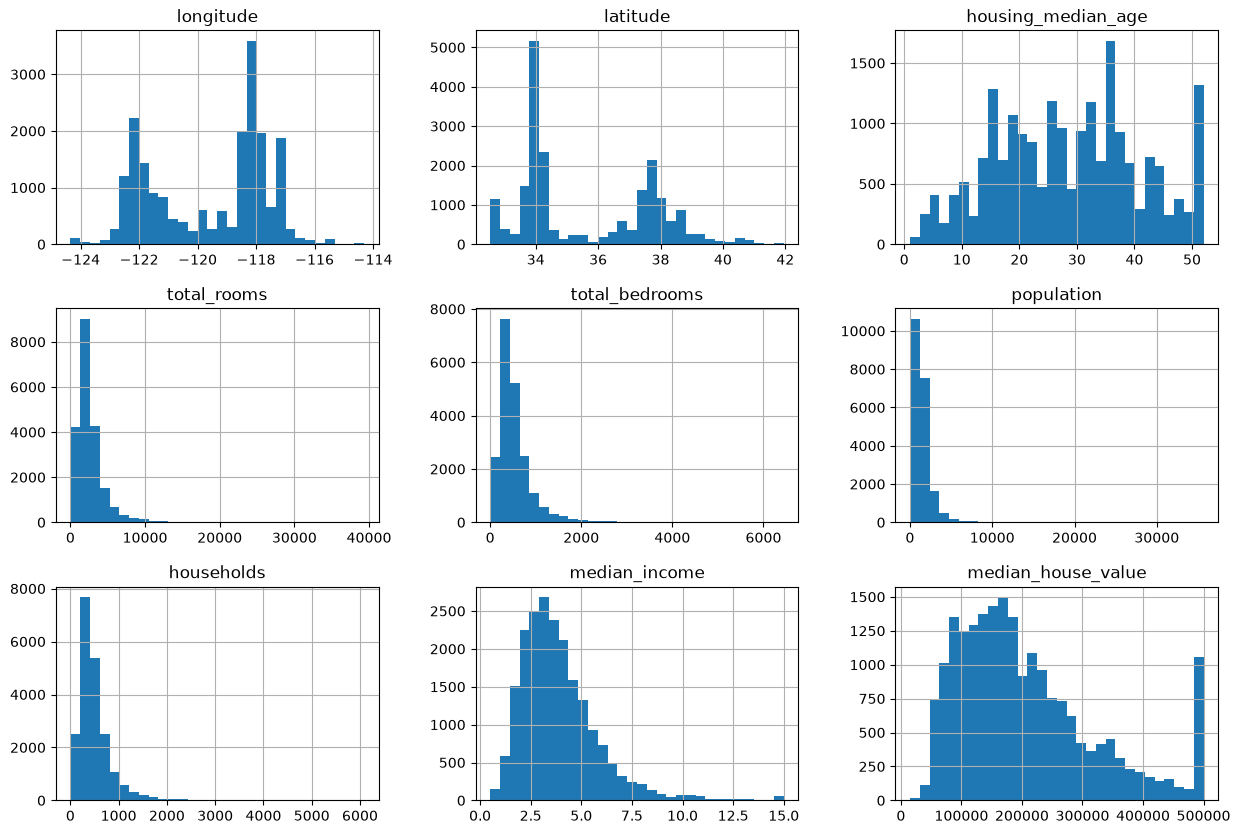

In [3]:
datos[columnas_numericas].hist(figsize=(15,10), bins=30)
plt.show()

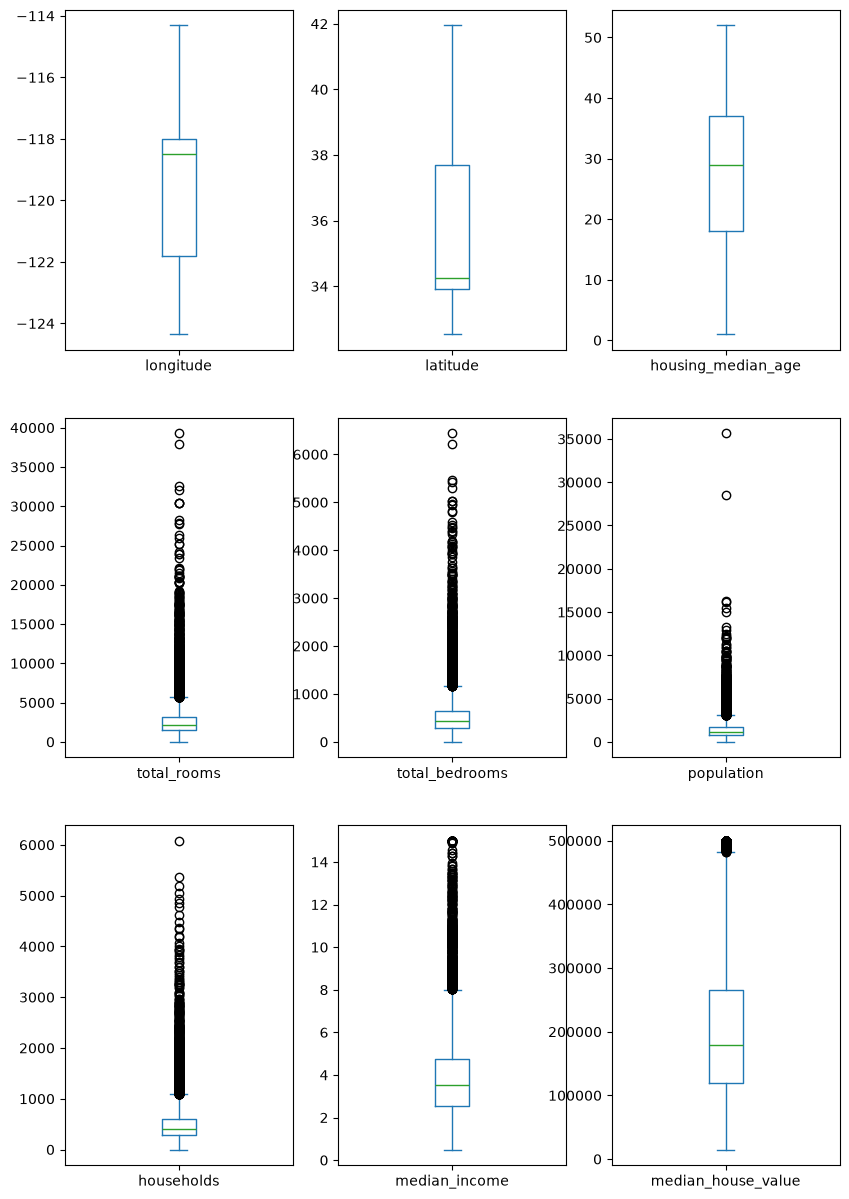

In [4]:
datos.plot(
    kind='box', 
    subplots=True, 
    sharey=False, 
    figsize=(10, 15),
    layout=(3,3)
)

plt.show()

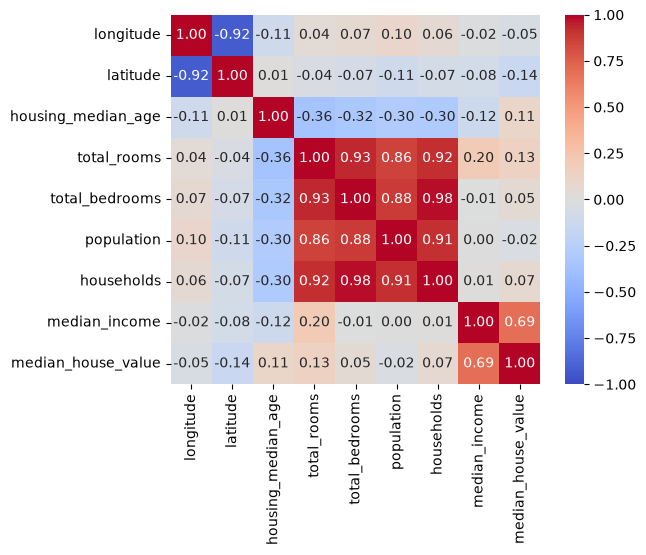

In [5]:
sns.heatmap(
    datos[columnas_numericas].corr(), annot=True, fmt=".2f", cmap='coolwarm', 
    vmin=-1, vmax=1, square=True)
plt.show()

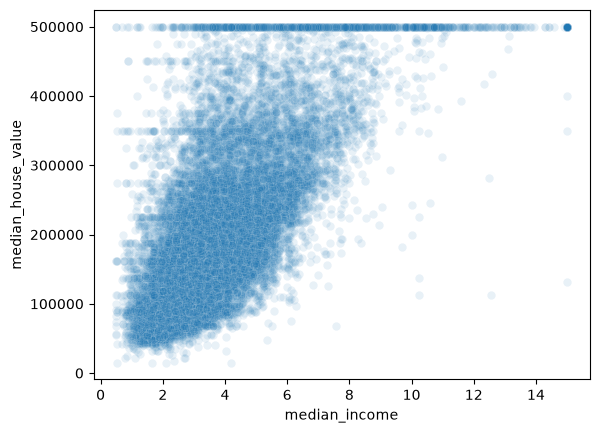

In [6]:
sns.scatterplot( data=datos, x='median_income', y='median_house_value', alpha=0.1)

plt.show()

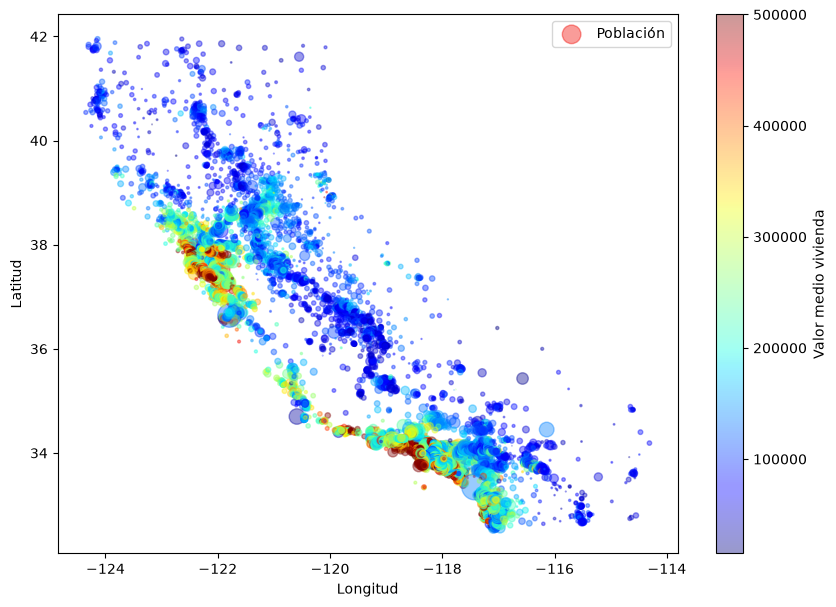

In [7]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(x=datos['longitude'], y=datos['latitude'], alpha=0.4,
                      s=datos['population']/100, label='Población',
                      c=datos['median_house_value'], cmap=plt.get_cmap('jet'))
plt.colorbar(scatter, label='Valor medio vivienda')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.show()

### Preprocesamiento de datos

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from category_encoders import BinaryEncoder

In [ ]:
# Clase para agrupar todas las funciones del preprocesado, así como los objetos
# necesarios para realizarlo.

class Preprocesado():

	escalador = StandardScaler()
	imputador = SimpleImputer(strategy='most_frequent') # Para que sea un numero entero
	codificador_binario = BinaryEncoder()

	@classmethod
	def transformar_lat_long(cls, datos):
		"""
		Transforma las columnas de la latitud y la longitud a coordenadas X, Y, Z
		y elimina la información original
		"""
		datos_coordenadas = datos[['longitude', 'latitude']].to_numpy()
		dimensiones = datos_coordenadas.shape

		datos_coordenadas_cartesianas = np.ndarray(shape=(dimensiones[0], 3), dtype=float)

		for fila in range(0, dimensiones[0]):
			longitud = datos_coordenadas[fila, 0]
			latitud = datos_coordenadas[fila, 1]

			datos_coordenadas_cartesianas[fila] = [
				np.cos(np.deg2rad(latitud)) * np.cos(np.deg2rad(longitud)),
				np.cos(np.deg2rad(latitud)) * np.sin(np.deg2rad(longitud)),
				np.sin(np.deg2rad(latitud))
			]

		datos[['x', 'y', 'z']] = datos_coordenadas_cartesianas
		datos.drop(columns=['longitude', 'latitude'], inplace=True)
			
		return datos

	@classmethod
	def completar_datos(cls, datos_entr = None, datos_test = None):
		"""
		Interpola los datos faltantes en la variable total_bedrooms
		"""
		if datos_entr is not None:
			datos_entr[['total_bedrooms']] = cls.imputador.fit_transform(datos_entr[['total_bedrooms']])

		if datos_test is not None:
			datos_test[['total_bedrooms']] = cls.imputador.transform(datos_test[['total_bedrooms']])

		return datos_entr, datos_test

	@classmethod
	def aplicar_log(cls, datos):
		"""
		Aplica el logaritmo natural a las columnas indicadas
		"""
		columnas = ['total_rooms', 'total_bedrooms', 'population', 'households',
			  'median_income', 'median_house_value']

		datos[columnas] = datos[columnas].apply(lambda x: np.log(x))

		return datos

	@classmethod
	def aplicar_codificacion_binaria(cls, datos_entr = None, datos_test = None):
		"""
		Transforma la variable categorica a una codificación binaria.
		"""
		if datos_entr is not None:
			categorias_binarias_ocean = cls.codificador_binario.fit_transform(datos_entr[['ocean_proximity']])
			datos_entr[categorias_binarias_ocean.columns] = categorias_binarias_ocean
			datos_entr.drop(columns=['ocean_proximity'], inplace=True)

		if datos_test is not None:
			categorias_binarias_ocean = cls.codificador_binario.transform(datos_test[['ocean_proximity']])
			datos_test[categorias_binarias_ocean.columns] = categorias_binarias_ocean
			datos_test.drop(columns=['ocean_proximity'], inplace=True)

		return datos_entr, datos_test

	@classmethod
	def aplicar_escalador_normal(cls, datos_entr = None, datos_test = None):
		"""
		Aplicar un escalado basado en una ditribución normal a los datos
		"""
		columnas = ['housing_median_age', 'total_rooms', 
			'total_bedrooms', 'population', 'households', 
			'median_income', 'median_house_value']

		if datos_entr is not None:
			datos_entr[columnas] = cls.escalador.fit_transform(datos_entr[columnas])
			
		if datos_test is not None:
			datos_test[columnas] = cls.escalador.transform(datos_test[columnas])

		return datos_entr, datos_test


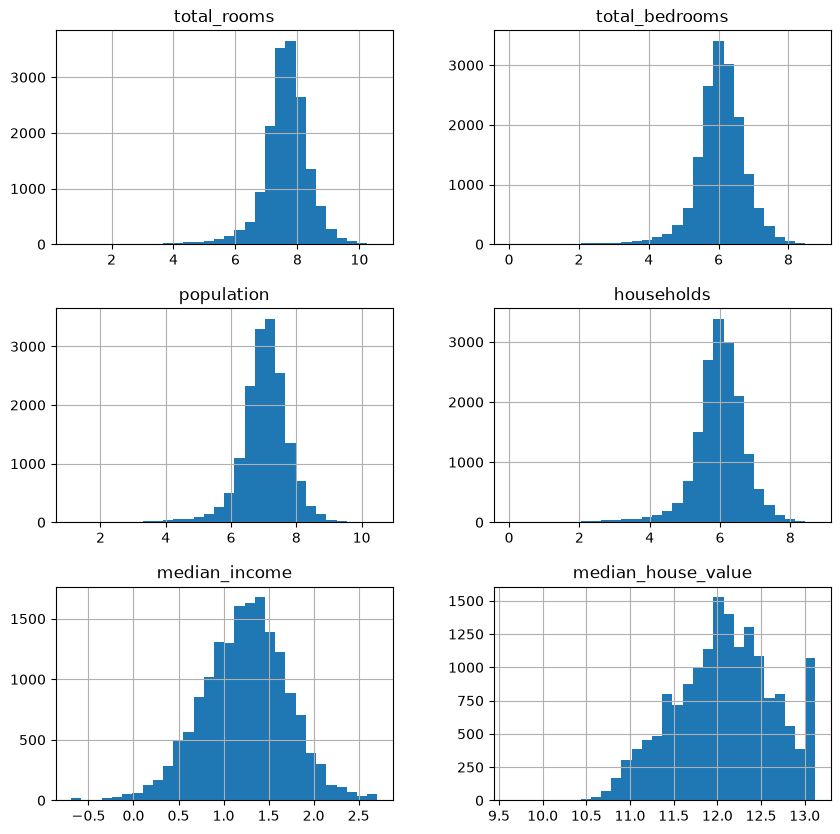

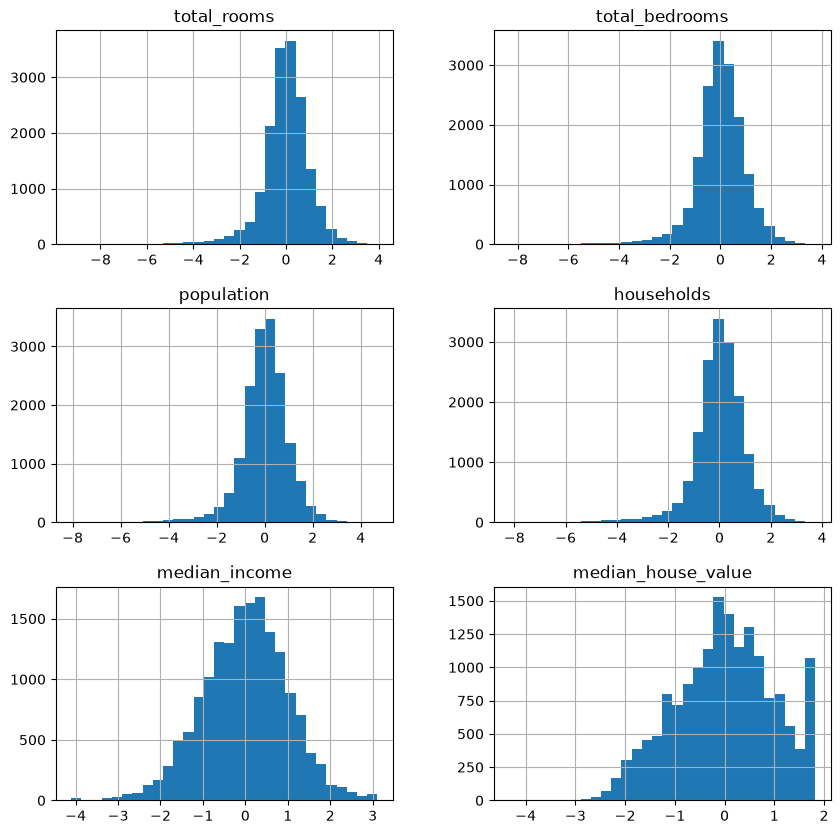

In [ ]:
# Para las pruebas tenía esto aquí.
# datos = pd.read_csv('housing.csv', sep=',')

# Paso 1
datos = Preprocesado.transformar_lat_long(datos)

# Paso 2
datos = Preprocesado.aplicar_log(datos)


# Paso 3. Dividir datos para entrenamiento y test
datos_entr, datos_test = train_test_split(
	datos, test_size=0.2, stratify=datos["ocean_proximity"], random_state=0
)

# Paso 4
datos_entr, datos_test = Preprocesado.aplicar_codificacion_binaria(datos_entr, datos_test)

# Paso 5
datos_entr, datos_test = Preprocesado.completar_datos(datos_entr, datos_test)

datos_entr[['total_rooms', 'total_bedrooms', 'population', 'households',
			  'median_income', 'median_house_value']].hist(figsize=(10,10), bins=30)
plt.show()

# Paso 6
datos_entr, datos_test = Preprocesado.aplicar_escalador_normal(datos_entr, datos_test)

datos_entr[['total_rooms', 'total_bedrooms', 'population', 'households',
			  'median_income', 'median_house_value']].hist(figsize=(10,10), bins=30)
plt.show()

# Paso 7
y_entr = datos_entr['median_house_value']
datos_entr = datos_entr.drop(columns=['median_house_value'])
columans_datos_entrada = datos_entr.columns
datos_entr = datos_entr.to_numpy()

y_test = datos_test['median_house_value']
datos_test = datos_test.drop(columns=['median_house_value']).to_numpy()

___
## Fase de modelado

In [11]:
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

from sklearn.neighbors import KNeighborsRegressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import BaggingRegressor

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from sklearn.ensemble import VotingRegressor

# Almacenamiento de las listas con los resultados de la cross-validación.
resultados_cv = {
    'rf'	: None,
	'et'	: None,
	'br_knn': None,
	'gb'	: None,
	'ab'	: None,
	'lgbm'	: None,
	'xgb'	: None,
	'vting'	: None
}

### Bagging

In [12]:
# Modelos usados que siguen la taxonomía bagging

rf = RandomForestRegressor()
resultados_cv['rf'] = cross_val_score(
    estimator = rf, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

et = ExtraTreesRegressor()
resultados_cv['et'] = cross_val_score(
    estimator = et, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

br_knn = BaggingRegressor(KNeighborsRegressor(n_neighbors=3), n_estimators=100)
resultados_cv['br_knn'] = cross_val_score(
    estimator = br_knn, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

### Boosting

In [17]:
# Modelos usados que siguen la taxonomía boosting

gb = GradientBoostingRegressor()
resultados_cv['gb'] = cross_val_score(
    estimator = gb, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

ab = AdaBoostRegressor()
resultados_cv['ab'] = cross_val_score(
    estimator = ab, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

lgbm = LGBMRegressor(verbose=-1)
resultados_cv['lgbm'] = cross_val_score(
    estimator = lgbm, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

xgb = XGBRegressor()
resultados_cv['xgb'] = cross_val_score(
    estimator = xgb, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

### Voting

In [18]:
# Modelo de la taxonomía por votación

vting = VotingRegressor(
    estimators = [
        ('rf', RandomForestRegressor()),
        ('et', ExtraTreesRegressor()),
        ('gb', GradientBoostingRegressor()),
        ('ab', AdaBoostRegressor()),
        ('lgbm', LGBMRegressor(verbose=-1))
	]
)
resultados_cv['vting'] = cross_val_score(
    estimator = vting, 
    X 		= datos_entr, 
    y 		= y_entr, 
    cv 		= KFold(n_splits=10, random_state=0, shuffle=True),
    scoring = 'neg_mean_squared_error'
)

### Resultados CV

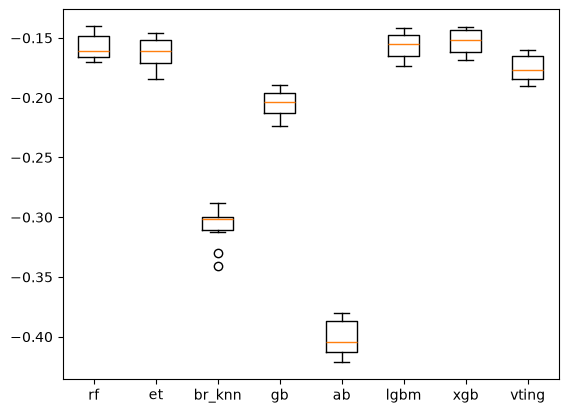

In [19]:
# Visualización de la distribución de los errores CV cometidos por cada modelo

fig = plt.figure()
ax = fig.add_subplot(111)
plt.boxplot(list(resultados_cv.values()))
ax.set_xticklabels(list(resultados_cv.keys()))
plt.show()

___
## Fase de optimización

In [22]:
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

import joblib

In [ ]:
resultado_busqueda = {}

# Deifinición de los ámbitos de búsqueda para los hiperparámetros
busquedas_params = {
    'rf': (RandomForestRegressor(random_state=0, bootstrap=True), {
        'n_estimators': [100, 200, 300],
        'max_depth': [1, 5, 10, 20],
        'max_features' : [1.0, 0.8, 0.6, 0.4, 0.2],
        'max_samples' : [1.0, 0.75, 0.5]
    }),
    'et': (ExtraTreesRegressor(random_state=0, bootstrap=True), {
        'n_estimators': [100, 200, 300],
        'max_depth': [1, 5, 10, 20],
        'max_features' : [1.0, 0.8, 0.6, 0.4, 0.2],
        'max_samples' : [1.0, 0.75, 0.5]
    }),
    'lgbm': (LGBMRegressor(random_state=0, verbose=-1), {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.025, 0.05, 0.1],
        'max_depth': [1, 3, 5, 7, 15]
    }),
    'xgb': (XGBRegressor(random_state=0), {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.025, 0.05, 0.1],
        'max_depth': [1, 3, 5, 7, 15]
    }),
    'gb': (GradientBoostingRegressor(random_state=0), {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.025, 0.05, 0.1],
        'max_depth': [1, 3, 5, 7, 15]
    }),
    'ab': (AdaBoostRegressor(random_state=0), {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.025, 0.05, 0.1]
    })
}

In [ ]:
# Búsqueada de la mejor configuración.
for nombre, (modelo, params) in busquedas_params.items():
	search = GridSearchCV(
		estimator=modelo, 
		param_grid=params, 
		cv=3, 
		scoring='neg_mean_squared_error',
		n_jobs=-1
	)
	
	search.fit(datos_entr, y_entr)

	resultado_busqueda[nombre] = search

In [90]:
# Construcción del modelo por votación
vting = VotingRegressor(
    estimators=[
        ('rf', clone(resultado_busqueda['rf'].best_estimator_)),
        ('et', clone(resultado_busqueda['et'].best_estimator_)),
        ('gb', clone(resultado_busqueda['gb'].best_estimator_)),
        ('ab', clone(resultado_busqueda['ab'].best_estimator_)),
        ('lgbm', clone(resultado_busqueda['lgbm'].best_estimator_))
    ],
    weights=[4, 3, 2, 1, 5]
)

vting.fit(datos_entr, y_entr)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('rf', ...), ('et', ...), ...]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.","[4, 3, ...]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[RandomForestR...andom_state=0), ExtraTreesReg...andom_state=0), GradientBoost...andom_state=0), AdaBoostRegre...andom_state=0), ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,12
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,"{'rf': Random..., verbose=-1)}"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.4


In [ ]:
# Mejor configuración de cada modelo
for key in resultado_busqueda.keys():
    print(key, resultado_busqueda[key].best_params_)

rf {'max_depth': 20, 'max_features': 0.4, 'max_samples': 1.0, 'n_estimators': 200}
et {'max_depth': 20, 'max_features': 0.6, 'max_samples': 1.0, 'n_estimators': 300}
lgbm {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300}
xgb {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300}
gb {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300}
ab {'learning_rate': 0.01, 'n_estimators': 300}


In [ ]:
# Almacenamiento de los modelos

# joblib.dump(resultado_busqueda['rf'].best_estimator_, 'rf.joblib')
# joblib.dump(resultado_busqueda['et'].best_estimator_, 'et.joblib')
# joblib.dump(resultado_busqueda['lgbm'].best_estimator_, 'lgbm.joblib')
# joblib.dump(resultado_busqueda['xgb'].best_estimator_, 'xgb.joblib')
# joblib.dump(resultado_busqueda['gb'].best_estimator_, 'gb.joblib')
# joblib.dump(resultado_busqueda['ab'].best_estimator_, 'ab.joblib')
# joblib.dump(vting, 'vting.joblib')

In [23]:
# Carga de los modelos

modelos = {}

modelos['rf'] = joblib.load('rf.joblib')
modelos['et'] = joblib.load('et.joblib')
modelos['lgbm'] = joblib.load('lgbm.joblib')
modelos['xgb'] = joblib.load('xgb.joblib')
modelos['vting'] = joblib.load('vting.joblib')

In [24]:
error_predicciones = {}

for key in modelos.keys():
	y_pred = modelos[key].predict(datos_test)
	error_predicciones[key] = mean_squared_error(y_test, y_pred)

	print(key, error_predicciones[key])

rf 0.14942742436067363
et 0.1636176943673685
lgbm 0.1462086726728661
xgb 0.14980319007789605
vting 0.1459740904360488


In [ ]:
error_cuadratico = {}

for key in modelos.keys():
	y_pred = modelos[key].predict(datos_test)
	error_cuadratico[key] = np.power(y_pred - y_test, 2)

error_cuadratico_df = pd.DataFrame(error_cuadratico)

In [53]:
(error_cuadratico_df.describe().T.round(5))[['mean', 'std', '50%', 'max']]

,mean,std,50%,max
rf,0.14943,0.45522,0.03477,11.14059
et,0.16362,0.46325,0.04177,11.70051
lgbm,0.14621,0.45478,0.03260,12.59000
xgb,0.14980,0.49899,0.03296,13.77568
vting,0.14597,0.44617,0.03535,11.70814


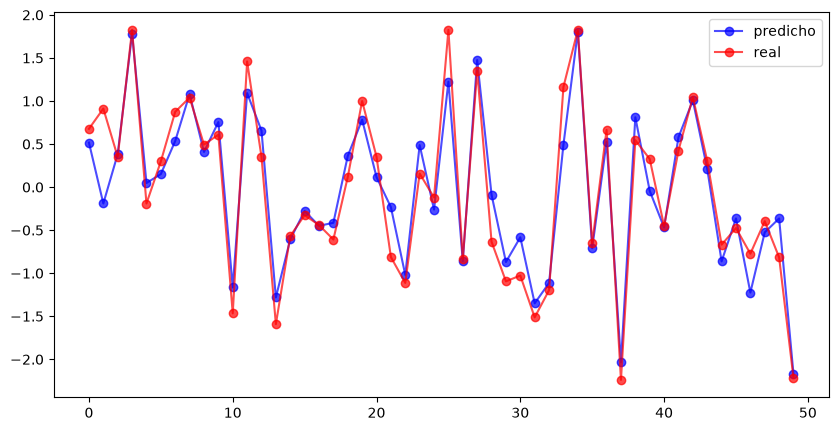

In [ ]:
# Ejemplo de la predicción realizada por el modelo voting

n_ejemplos = 50

y_pred = modelos['vting'].predict(datos_test)

eje_x = list(range(n_ejemplos))

plt.figure(figsize=(10, 5))

plt.plot(eje_x, y_pred[:n_ejemplos], label='predicho', color='blue', marker='o', alpha=0.7)
plt.plot(eje_x, y_test[:n_ejemplos], label='real', color='red', marker='o', alpha=0.7)
plt.legend(fontsize=10)
plt.show()

## Explicabilidad e interpretabilidad en Ensemble

In [67]:
from sklearn.inspection import permutation_importance

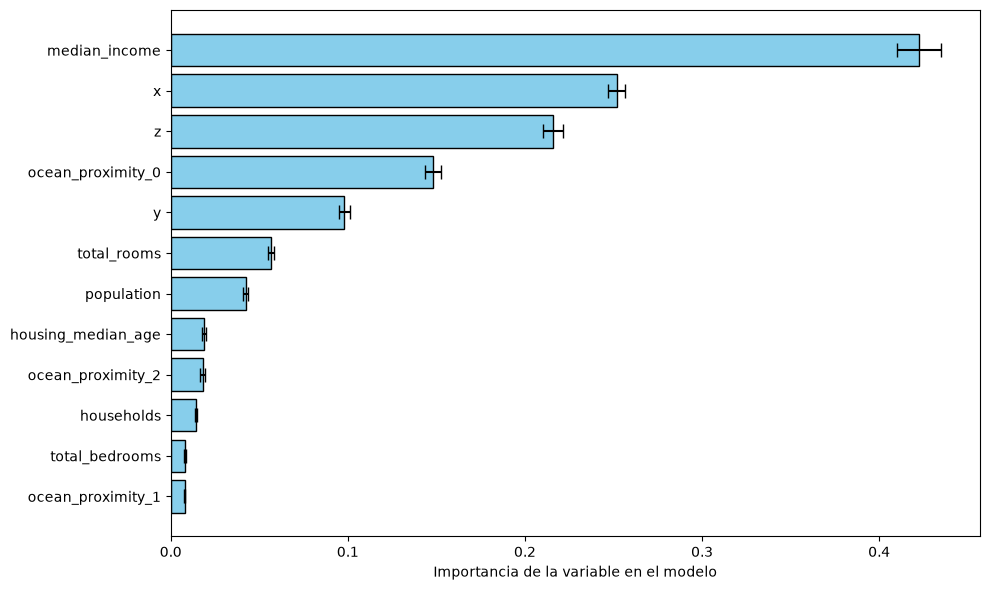

In [80]:
# Calculo de la importancia por característica 
resultados_permutacion = permutation_importance(
    estimator	= modelos['vting'], 
    X			= datos_test, 
    y			= y_test,
    scoring		= 'neg_mean_squared_error',
    n_repeats	= 10,
    random_state= 0, 
    n_jobs		= -1
)

importancia_caracteristicas = pd.DataFrame({
    'caracteristica': columans_datos_entrada,
    'importancia_media': resultados_permutacion.importances_mean,
    'std': resultados_permutacion.importances_std
})

# Ordenación según afectó
importancia_caracteristicas = importancia_caracteristicas.sort_values(by='importancia_media', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importancia_caracteristicas['caracteristica'], importancia_caracteristicas['importancia_media'], 
         xerr=importancia_caracteristicas['std'], capsize=5, color='skyblue', edgecolor='black')
plt.xlabel('Importancia de la variable en el modelo')
plt.tight_layout()
plt.show()

In [106]:
df_clases = pd.DataFrame(data=datos['ocean_proximity'].unique(), columns=['ocean_proximity'])

df_codificado = Preprocesado.codificador_binario.transform(df_clases)

pd.concat([df_clases, df_codificado], axis=1)

,ocean_proximity,ocean_proximity_0,ocean_proximity_1,ocean_proximity_2
0,NEAR BAY,0,1,0
1,<1H OCEAN,0,0,1
2,INLAND,1,0,0
3,NEAR OCEAN,0,1,1
4,ISLAND,1,0,1
